# 02 · Fashion-MNIST: Hyperparameter Search, Entropy-Regularised Loss and SAM

> Curated from my completed FIT3181 (Monash University) Assignment 1 notebook. Code cells and their outputs are unchanged from the original Google Colab run; only explanatory markdown has been rewritten. Cells marked *provided* are unit starter code.

**Contents**
1. Mini-batch visualisation
2. Baseline MLP `784 → 40 (ReLU) → 30 (ReLU) → 10`
3. Grid search over hidden sizes and activation functions
4. Custom loss: cross-entropy plus an entropy term
5. Sharpness-Aware Minimization (SAM), implemented as a `torch.optim.Optimizer`

The data is split into 54,000 train, 6,000 validation (a random 90/10 split of the official training set) and 10,000 test images.

## Data (*provided*)

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(1234)

In [ ]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

train_dataset_orgin = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

print(train_dataset_orgin.data.shape, train_dataset_orgin.targets.shape)
print(test_dataset.data.shape, test_dataset.targets.shape)

# Flatten the data
train_dataset_orgin.data = train_dataset_orgin.data.reshape(-1, 28*28)
test_dataset.data = test_dataset.data.reshape(-1, 28*28)

print(train_dataset_orgin.data.shape, train_dataset_orgin.targets.shape)
print(test_dataset.data.shape, test_dataset.targets.shape)

N = len(train_dataset_orgin)
print(f"Number of training samples: {N}")
N_train = int(0.9*N)
N_val = N - N_train
print(f"Number of training samples: {N_train}")
print(f"Number of validation samples: {N_val}")

train_dataset, val_dataset = torch.utils.data.random_split(train_dataset_orgin, [N_train, N_val])


print(len(train_dataset))
print(len(val_dataset))


train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=1000, shuffle=False)

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 306kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.54MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.7MB/s]

torch.Size([60000, 28, 28]) torch.Size([60000])
torch.Size([10000, 28, 28]) torch.Size([10000])
torch.Size([60000, 784]) torch.Size([60000])
torch.Size([10000, 784]) torch.Size([10000])
Number of training samples: 60000
Number of training samples: 54000
Number of validation samples: 6000
54000
6000


## 1. Visualising a mini-batch

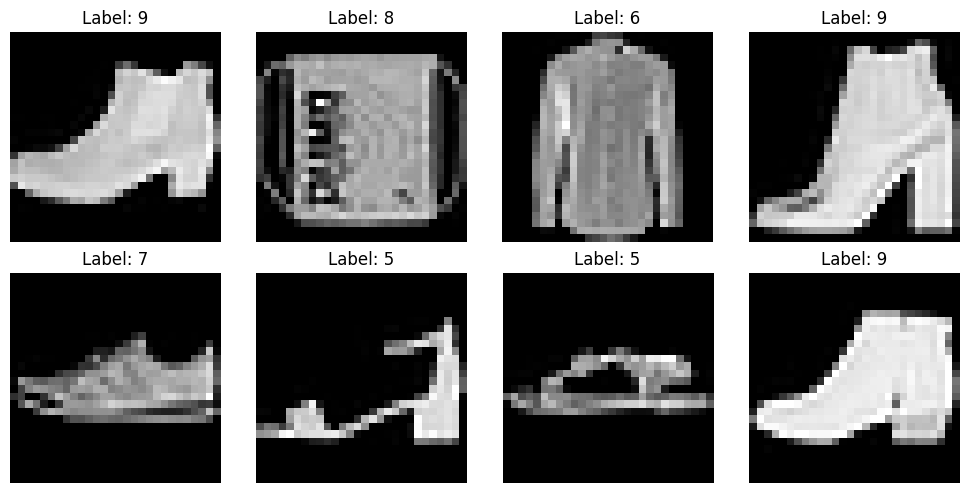

In [ ]:
import matplotlib.pyplot as plt

# Get one mini-batch
images, labels = next(iter(train_loader))

# Plot the first 8 images
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flatten()):
  image = images[i].reshape(28, 28)

  ax.imshow(image, cmap='gray')
  ax.set_title(f"Label: {labels[i].item()}")
  ax.axis('off')

plt.tight_layout()
plt.show()

## 2. Baseline MLP (Adam, lr = 1e-3, 50 epochs)

The train metrics are running averages over each epoch, and the test set is evaluated once at the end.

In [ ]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Build the FFN
model = nn.Sequential(
    nn.Linear(28*28, 40),
    nn.ReLU(),
    nn.Linear(40, 30),
    nn.ReLU(),
    nn.Linear(30, 10)
).to(device)

# Loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Train for 50 epochs
num_epochs = 50

for epoch in range(num_epochs):
  model.train()

  total_loss = 0.0
  correct = 0
  total = 0

  for x, y in train_loader:
      x = x.view(x.size(0), -1).to(device).float()
      y = y.to(device).long()

      # Forward propagation
      logits = model(x)
      loss = loss_fn(logits, y)

      # Backpropagation
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      # Record training loss
      total_loss += loss.item() * x.size(0)

      # Record training accuracy
      predicted = torch.argmax(logits, dim=1)
      correct += (predicted == y).sum().item()
      total += y.size(0)

  train_loss = total_loss / total
  train_acc = correct / total

  print(
      f"Epoch {epoch+1}/{num_epochs}, "
      f"Train Loss: {train_loss:.4f}, "
      f"Train Acc: {train_acc*100:.2f}%"
  )

model.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
  for x, y in test_loader:
    x = x.view(x.size(0), -1).to(device).float()
    y = y.to(device).long()

    logits = model(x)
    loss = loss_fn(logits, y)

    test_loss += loss.item() * x.size(0)

    predicted = torch.argmax(logits, dim=1)

    correct += (predicted == y).sum().item()
    total += y.size(0)

test_loss = test_loss / total
test_acc = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc*100:.2f}%")


Epoch 1/50, Train Loss: 0.5983, Train Acc: 78.58%
Epoch 2/50, Train Loss: 0.4194, Train Acc: 84.67%
Epoch 3/50, Train Loss: 0.3756, Train Acc: 86.28%
Epoch 4/50, Train Loss: 0.3502, Train Acc: 87.20%
Epoch 5/50, Train Loss: 0.3347, Train Acc: 87.75%
Epoch 6/50, Train Loss: 0.3178, Train Acc: 88.23%
Epoch 7/50, Train Loss: 0.3079, Train Acc: 88.69%
Epoch 8/50, Train Loss: 0.2967, Train Acc: 88.99%
Epoch 9/50, Train Loss: 0.2924, Train Acc: 89.23%
Epoch 10/50, Train Loss: 0.2833, Train Acc: 89.43%
Epoch 11/50, Train Loss: 0.2755, Train Acc: 89.83%
Epoch 12/50, Train Loss: 0.2678, Train Acc: 89.97%
Epoch 13/50, Train Loss: 0.2647, Train Acc: 90.14%
Epoch 14/50, Train Loss: 0.2584, Train Acc: 90.34%
Epoch 15/50, Train Loss: 0.2548, Train Acc: 90.51%
Epoch 16/50, Train Loss: 0.2490, Train Acc: 90.70%
Epoch 17/50, Train Loss: 0.2430, Train Acc: 90.90%
Epoch 18/50, Train Loss: 0.2396, Train Acc: 91.09%
Epoch 19/50, Train Loss: 0.2344, Train Acc: 91.21%
Epoch 20/50, Train Loss: 0.2307, Train A

## 3. Grid search

The search covers $n_1 \in \{20, 40\}$, $n_2 \in \{20, 40\}$ and the activation $\in$ {Sigmoid, Tanh, ReLU}, which is 12 configurations. Each is trained for 10 epochs with Adam (lr = 1e-3) and selected by validation accuracy.

In [ ]:
hidden1_options = [20, 40]
hidden2_options = [20, 40]

activation_options = {
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh(),
    "ReLU": nn.ReLU()
}

best_val_acc = 0
best_config = None
best_model = None

for n1 in hidden1_options:
  for n2 in hidden2_options:
    for act_name, act in activation_options.items():

      # Create fresh model
      model = nn.Sequential(
          nn.Linear(28*28, n1),
          act,
          nn.Linear(n1, n2),
          act,
          nn.Linear(n2, 10)
      ).to(device)

      loss_fn = nn.CrossEntropyLoss()
      optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

      # Train model
      num_epochs = 10

      for epoch in range(num_epochs):
        model.train()

        for x, y in train_loader:
          x = x.view(x.size(0), -1).to(device).float()
          y = y.to(device).long()

          # Forward propagation
          logits = model(x)
          loss = loss_fn(logits, y)

          # Backpropagation
          optimizer.zero_grad()
          loss.backward()
          optimizer.step()

      # Validation
      model.eval()

      correct = 0
      total = 0

      with torch.no_grad():
        for x, y in val_loader:
          x = x.view(x.size(0), -1).to(device).float()
          y = y.to(device).long()

          logits = model(x)
          predicted = torch.argmax(logits, dim=1)

          correct += (predicted == y).sum().item()
          total += y.size(0)

      val_acc = correct / total

      print(
          f"n1={n1}, n2={n2}, activation={act_name}, "
          f"Val Acc={val_acc*100:.2f}%"
      )

      # Save best configuration
      if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_config = (n1, n2, act_name)
        best_model = model

print("\nBest configuration:")
print(f"n1={best_config[0]}")
print(f"n2={best_config[1]}")
print(f"Activation={best_config[2]}")
print(f"Validation Accuracy={best_val_acc*100:.2f}%")


n1=20, n2=20, activation=Sigmoid, Val Acc=85.45%
n1=20, n2=20, activation=Tanh, Val Acc=85.83%
n1=20, n2=20, activation=ReLU, Val Acc=86.00%
n1=20, n2=40, activation=Sigmoid, Val Acc=85.87%
n1=20, n2=40, activation=Tanh, Val Acc=85.35%
n1=20, n2=40, activation=ReLU, Val Acc=86.07%
n1=40, n2=20, activation=Sigmoid, Val Acc=86.98%
n1=40, n2=20, activation=Tanh, Val Acc=86.27%
n1=40, n2=20, activation=ReLU, Val Acc=87.13%
n1=40, n2=40, activation=Sigmoid, Val Acc=86.78%
n1=40, n2=40, activation=Tanh, Val Acc=87.48%
n1=40, n2=40, activation=ReLU, Val Acc=87.23%

Best configuration:
n1=40
n2=40
Activation=Tanh
Validation Accuracy=87.48%


## 4. Cross-entropy with an entropy term (λ = 0.1)

$$\mathcal{L}(p, y) = \text{CE}(\mathbf{1}_y, p) + \lambda\, H(p), \qquad H(p) = -\sum_i p_i \log p_i$$

With a positive λ, this term penalises high-entropy (uncertain) predictions and pushes the model towards more confident outputs. The reported test loss includes the entropy term, so it is not directly comparable to the plain cross-entropy test loss of the baseline.

In [ ]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def custom_loss(logits, y, lam=0.1):

  # Cross-entropy loss
  ce_loss = nn.functional.cross_entropy(logits, y)

  # Convert logits to probabilities
  p = torch.softmax(logits, dim=1)

  # Entropy H(p)
  entropy = -(p * torch.log(p + 1e-8)).sum(dim=1).mean()

  # Final loss
  loss = ce_loss + lam * entropy

  return loss

# Build model
model_entropy = nn.Sequential(
    nn.Linear(28*28, 40),
    nn.ReLU(),
    nn.Linear(40, 30),
    nn.ReLU(),
    nn.Linear(30, 10)
).to(device)

# Optimizer
optimizer = torch.optim.Adam(
    model_entropy.parameters(),
    lr=0.001
)


# Train for 50 epochs
num_epochs = 50

for epoch in range(num_epochs):

  model_entropy.train()

  total_loss = 0.0
  correct = 0
  total = 0

  for x, y in train_loader:

    # Flatten images
    x = x.view(x.size(0), -1).to(device).float()
    y = y.to(device).long()

    # Forward propagation
    logits = model_entropy(x)

    # Compute custom loss
    loss = custom_loss(logits, y, lam=0.1)

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Record training loss
    total_loss += loss.item() * x.size(0)

    # Record training accuracy
    predicted = torch.argmax(logits, dim=1)
    correct += (predicted == y).sum().item()
    total += y.size(0)

  train_loss = total_loss / total
  train_acc = correct / total

  print(
      f"Epoch {epoch+1}/{num_epochs}, "
      f"Train Loss: {train_loss:.4f}, "
      f"Train Acc: {train_acc*100:.2f}%"
  )


# Test evaluation
model_entropy.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
  for x, y in test_loader:

    # Flatten images
    x = x.view(x.size(0), -1).to(device).float()
    y = y.to(device).long()

    # Forward propagation
    logits = model_entropy(x)

    # Compute custom loss
    loss = custom_loss(logits, y, lam=0.1)

    # Record test loss
    test_loss += loss.item() * x.size(0)

    # Record test accuracy
    predicted = torch.argmax(logits, dim=1)

    correct += (predicted == y).sum().item()
    total += y.size(0)


test_loss = test_loss / total
test_acc = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc*100:.2f}%")

Epoch 1/50, Train Loss: 0.6367, Train Acc: 79.16%
Epoch 2/50, Train Loss: 0.4555, Train Acc: 84.94%
Epoch 3/50, Train Loss: 0.4155, Train Acc: 86.16%
Epoch 4/50, Train Loss: 0.3900, Train Acc: 86.85%
Epoch 5/50, Train Loss: 0.3692, Train Acc: 87.73%
Epoch 6/50, Train Loss: 0.3549, Train Acc: 88.06%
Epoch 7/50, Train Loss: 0.3434, Train Acc: 88.44%
Epoch 8/50, Train Loss: 0.3345, Train Acc: 88.91%
Epoch 9/50, Train Loss: 0.3218, Train Acc: 89.05%
Epoch 10/50, Train Loss: 0.3125, Train Acc: 89.35%
Epoch 11/50, Train Loss: 0.3059, Train Acc: 89.70%
Epoch 12/50, Train Loss: 0.3000, Train Acc: 89.86%
Epoch 13/50, Train Loss: 0.2947, Train Acc: 89.88%
Epoch 14/50, Train Loss: 0.2880, Train Acc: 90.26%
Epoch 15/50, Train Loss: 0.2827, Train Acc: 90.38%
Epoch 16/50, Train Loss: 0.2793, Train Acc: 90.49%
Epoch 17/50, Train Loss: 0.2729, Train Acc: 90.68%
Epoch 18/50, Train Loss: 0.2674, Train Acc: 90.84%
Epoch 19/50, Train Loss: 0.2637, Train Acc: 91.11%
Epoch 20/50, Train Loss: 0.2587, Train A

## 5. Sharpness-Aware Minimization

SAM (Foret et al., 2021) minimises $\max_{\lVert\epsilon\rVert_2 \le \rho} \mathcal{L}(w + \epsilon)$ using a two-pass update:

1. Compute $g = \nabla \mathcal{L}(w)$, then move to $w + \hat\epsilon$ with $\hat\epsilon = \rho\, g / \lVert g \rVert_2$ (`first_step`).
2. Compute the gradient at $w + \hat\epsilon$, restore $w$, and apply the base optimiser step with that gradient (`second_step`).

The model is applied to the best grid-search architecture (`784 → 40 (Tanh) → 40 (Tanh) → 10`), with SGD (lr = 0.01, momentum = 0.9) as the base optimiser and ρ = 0.05, for 50 epochs.

In [ ]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Sharpness-Aware Minimization (SAM)
class SAM(torch.optim.Optimizer):
  def __init__(self, params, base_optimizer, rho=0.05, **kwargs):

    if rho < 0.0:
      raise ValueError("rho must be non-negative")

    defaults = dict(rho=rho, **kwargs)
    super().__init__(params, defaults)

    self.base_optimizer = base_optimizer(self.param_groups, **kwargs)

  @torch.no_grad()
  def first_step(self, zero_grad=False):

    # Compute the L2 norm of all gradients
    grad_norm = torch.norm(
        torch.stack([
            p.grad.norm(p=2)
            for group in self.param_groups
            for p in group["params"]
            if p.grad is not None
        ]),
        p=2
    )

    # Perturb the model parameters
    for group in self.param_groups:
      scale = group["rho"] / (grad_norm + 1e-12)

      for p in group["params"]:
        if p.grad is None:
          continue

        e_w = p.grad * scale
        p.add_(e_w)

        # Save perturbation so the original weights can be restored
        self.state[p]["e_w"] = e_w

    if zero_grad:
      self.zero_grad()

  @torch.no_grad()
  def second_step(self, zero_grad=False):

    # Restore the original parameters
    for group in self.param_groups:
      for p in group["params"]:
        if "e_w" not in self.state[p]:
          continue

        p.sub_(self.state[p]["e_w"])

    # Update original parameters using gradient at perturbed weights
    self.base_optimizer.step()

    if zero_grad:
      self.zero_grad()

  def step(self):
    raise NotImplementedError(
        "SAM requires first_step() and second_step()"
    )

# Best architecture from Q2.3:
# 784 -> 40(Tanh) -> 40(Tanh) -> 10
model_sam = nn.Sequential(
    nn.Linear(784, 40),
    nn.Tanh(),
    nn.Linear(40, 40),
    nn.Tanh(),
    nn.Linear(40, 10)
).to(device)


# Loss function
loss_fn = nn.CrossEntropyLoss()


# SAM using SGD as the base optimizer
optimizer_sam = SAM(
    model_sam.parameters(),
    torch.optim.SGD,
    rho=0.05,
    lr=0.01,
    momentum=0.9
)


# Train for 50 epochs
num_epochs = 50

for epoch in range(num_epochs):
  model_sam.train()

  total_loss = 0.0
  correct = 0
  total = 0

  for x, y in train_loader:

    # Flatten FashionMNIST images
    x = x.view(x.size(0), -1).to(device).float()
    y = y.to(device).long()


    # First forward/backward pass
    logits = model_sam(x)
    loss = loss_fn(logits, y)

    optimizer_sam.zero_grad()
    loss.backward()

    # Move to the nearby high-loss point
    optimizer_sam.first_step(zero_grad=True)


    # Second forward/backward pass at perturbed weights
    logits_second = model_sam(x)
    loss_second = loss_fn(logits_second, y)

    loss_second.backward()

    # Restore original weights and perform update
    optimizer_sam.second_step(zero_grad=True)


    # Record training performance
    total_loss += loss.item() * x.size(0)

    predicted = torch.argmax(logits, dim=1)

    correct += (predicted == y).sum().item()
    total += y.size(0)

  train_loss = total_loss / total
  train_acc = correct / total

  # Validation
  model_sam.eval()

  val_loss = 0.0
  val_correct = 0
  val_total = 0

  with torch.no_grad():

    for x, y in val_loader:

      x = x.view(x.size(0), -1).to(device).float()
      y = y.to(device).long()

      logits = model_sam(x)
      loss = loss_fn(logits, y)

      val_loss += loss.item() * x.size(0)

      predicted = torch.argmax(logits, dim=1)

      val_correct += (predicted == y).sum().item()
      val_total += y.size(0)


  val_loss = val_loss / val_total
  val_acc = val_correct / val_total


  print(
      f"Epoch {epoch+1}/{num_epochs}, "
      f"Train Loss: {train_loss:.4f}, "
      f"Train Acc: {train_acc*100:.2f}%, "
      f"Val Loss: {val_loss:.4f}, "
      f"Val Acc: {val_acc*100:.2f}%"
  )


# Final test evaluation
model_sam.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

  for x, y in test_loader:

    x = x.view(x.size(0), -1).to(device).float()
    y = y.to(device).long()

    logits = model_sam(x)
    loss = loss_fn(logits, y)

    test_loss += loss.item() * x.size(0)

    predicted = torch.argmax(logits, dim=1)

    correct += (predicted == y).sum().item()
    total += y.size(0)


test_loss = test_loss / total
test_acc = correct / total

print(
    f"Test Loss: {test_loss:.4f}, "
    f"Test Accuracy: {test_acc*100:.2f}%"
)

Epoch 1/50, Train Loss: 0.6307, Train Acc: 78.31%, Val Loss: 0.4807, Val Acc: 82.68%
Epoch 2/50, Train Loss: 0.4252, Train Acc: 84.61%, Val Loss: 0.4300, Val Acc: 84.70%
Epoch 3/50, Train Loss: 0.3880, Train Acc: 86.05%, Val Loss: 0.4054, Val Acc: 85.45%
Epoch 4/50, Train Loss: 0.3635, Train Acc: 86.89%, Val Loss: 0.3965, Val Acc: 85.60%
Epoch 5/50, Train Loss: 0.3481, Train Acc: 87.31%, Val Loss: 0.3837, Val Acc: 85.95%
Epoch 6/50, Train Loss: 0.3324, Train Acc: 88.04%, Val Loss: 0.3766, Val Acc: 86.48%
Epoch 7/50, Train Loss: 0.3216, Train Acc: 88.37%, Val Loss: 0.3729, Val Acc: 86.98%
Epoch 8/50, Train Loss: 0.3137, Train Acc: 88.65%, Val Loss: 0.3628, Val Acc: 87.15%
Epoch 9/50, Train Loss: 0.3062, Train Acc: 88.96%, Val Loss: 0.3573, Val Acc: 87.47%
Epoch 10/50, Train Loss: 0.2984, Train Acc: 89.24%, Val Loss: 0.3621, Val Acc: 87.65%
Epoch 11/50, Train Loss: 0.2921, Train Acc: 89.34%, Val Loss: 0.3557, Val Acc: 87.48%
Epoch 12/50, Train Loss: 0.2872, Train Acc: 89.66%, Val Loss: 0